Read Dataset

In [87]:
import pandas as pd

In [88]:
df_balance = pd.read_csv('diabetes.csv')

In [89]:
df_balance

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [90]:
df_balance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [91]:
df_balance.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [92]:
pd.unique(df_balance['Outcome'])

array([1, 0])

In [93]:
df_balance['Outcome'].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

Split Dependent (Target/Label) Independent (atribut) Variable

In [94]:
x = df_balance.iloc[:,0:8].values
y = df_balance.iloc[:,[8]].values

In [95]:
y = y.reshape(len(y),)

Feature Scaling

In [96]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
x = scaler.fit_transform(x)


Split Train Test

In [97]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=0)

Klasifikasi KNN

In [98]:
from sklearn.neighbors import KNeighborsClassifier

Training / Fit Model

In [99]:
knn = KNeighborsClassifier(n_neighbors=20,metric='euclidean').fit(x_train,y_train)
knn 

,n_neighbors,20
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'euclidean'
,metric_params,None
,n_jobs,None


Prediksi / Test

In [100]:
y_prediksi = knn.predict(x_test)

In [101]:
y_prediksi

array([1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0])

Cek Akurasi dan Evaluasi

In [102]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import seaborn as sb

In [103]:
print("Nilai Akurasi ", accuracy_score(y_test,y_prediksi ))

Nilai Akurasi  0.8116883116883117


              precision    recall  f1-score   support

           0       0.82      0.93      0.87       107
           1       0.76      0.55      0.64        47

    accuracy                           0.81       154
   macro avg       0.79      0.74      0.76       154
weighted avg       0.81      0.81      0.80       154



<Axes: >

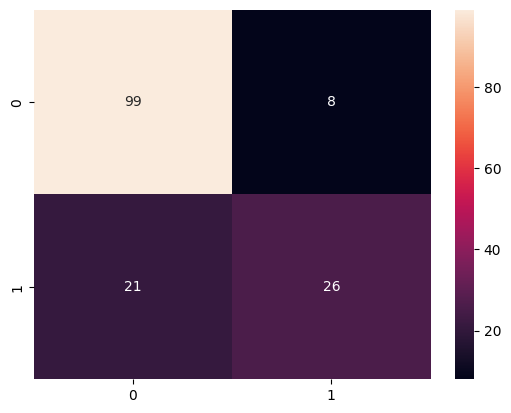

In [104]:
print(classification_report(y_test,y_prediksi))
sb.heatmap(confusion_matrix(y_test,y_prediksi),annot=True)


Mencari Nilai K Terbaik

In [105]:
n_akurasi = []
for k in range (1,30):
    knn = KNeighborsClassifier(n_neighbors=k,metric='euclidean').fit(x_train,y_train)
    y_prediksi = knn.predict(x_test)
    akurasi = accuracy_score(y_test,y_prediksi)
    n_akurasi.append(akurasi)
print(n_akurasi)

[0.6883116883116883, 0.7467532467532467, 0.7727272727272727, 0.7467532467532467, 0.7792207792207793, 0.7857142857142857, 0.7857142857142857, 0.7922077922077922, 0.8051948051948052, 0.7792207792207793, 0.7857142857142857, 0.7857142857142857, 0.7922077922077922, 0.7792207792207793, 0.7922077922077922, 0.7922077922077922, 0.8051948051948052, 0.7987012987012987, 0.7987012987012987, 0.8116883116883117, 0.8116883116883117, 0.7987012987012987, 0.7987012987012987, 0.7987012987012987, 0.7922077922077922, 0.7987012987012987, 0.7987012987012987, 0.8051948051948052, 0.7987012987012987]


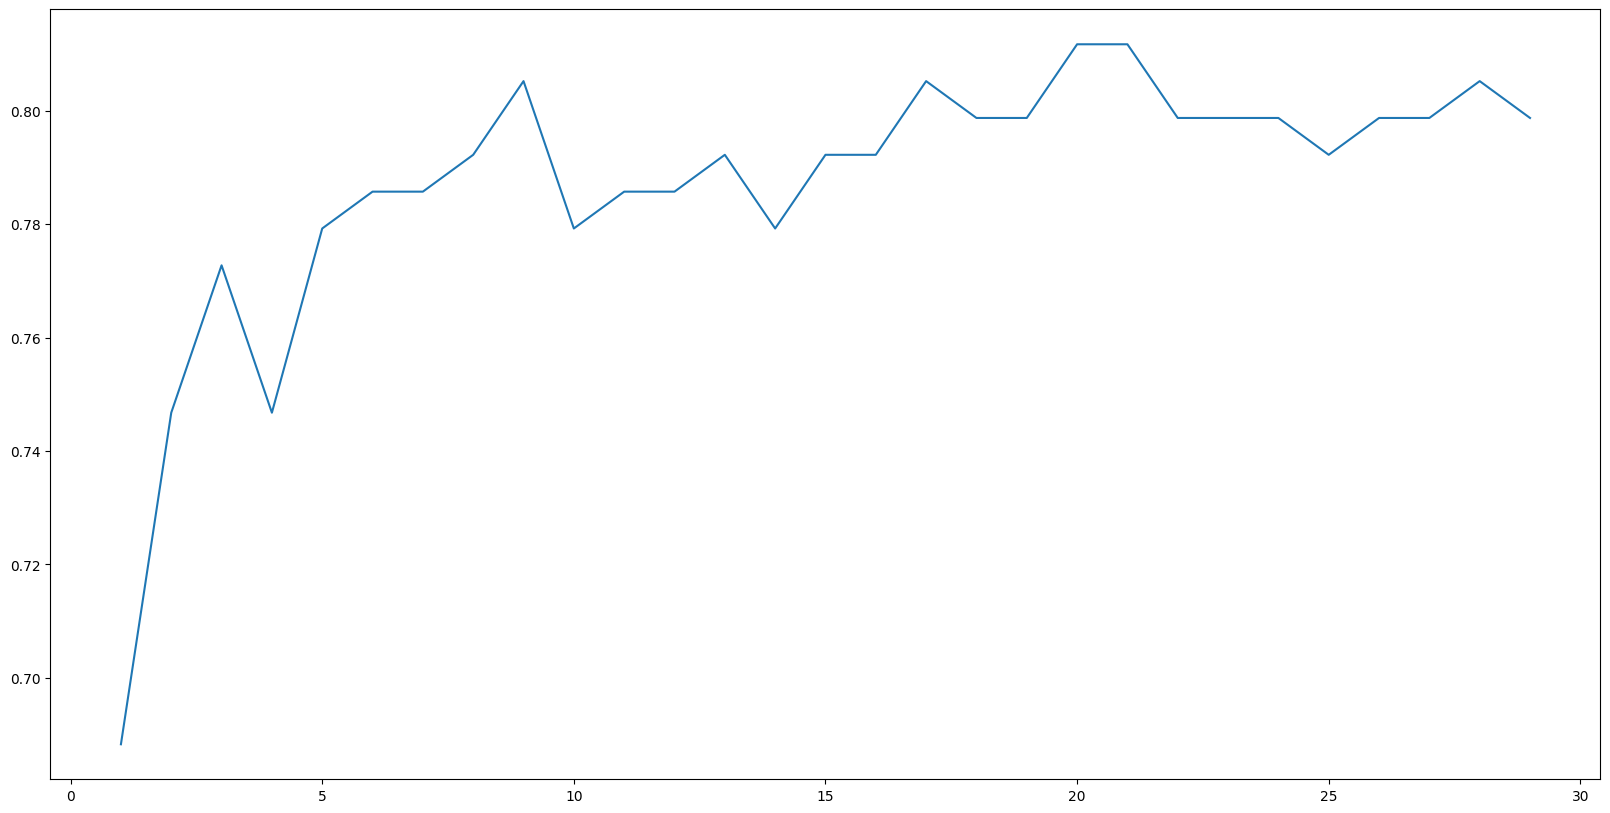

In [106]:
import matplotlib.pyplot as plt
plt.figure(figsize=(20,10))
plt.plot(range (1,30),n_akurasi)
plt.show()

Klasifikasi Data Baru

In [107]:
new_data = [[1,2,3,4,5,6,7,8]]
new_pred = knn.predict(new_data)
print(new_pred)

[1]
